# HW1 — Item 1: Standard deviation

This item compares **NumPy's** standard deviation with the estimator sheet.

The sample mean is $\bar{x} = \frac{1}{N}\sum_{i=1}^{N} x_i$

In [1]:
import numpy as np

This homework requires random 100 numbers to calculate standard deviations. To make our objective of comparing numpy's standard deviation with lecture 2 slide's formula's we choose a normal distribution with known standard deviation and mean. 
note: we use seed of "2026" for reproducibility purposes

In [2]:
rng = np.random.default_rng(2026)
a = rng.normal(10,2,100)

we check if the array consists 100 numbers and we generate first 5 numbers just to see

In [3]:
print(a.shape)     
print(a[:5])       

(100,)
[ 8.41375505 10.48114257  6.2073473  12.79154342 11.27658948]


We calculate standard deviation with N and N-1 by changing the ddof value from default "0" to "1".

In [4]:
std_pop    = a.std()
std_sample = a.std(ddof=1)

In [5]:
print(f"std()       = {std_pop:.6f}")
print(f"std(ddof=1) = {std_sample:.6f}")

std()       = 2.036969
std(ddof=1) = 2.047231


## Implementation

I implement the estimator from the Lecture 2 sheet:

$s^2 = \frac{1}{N-1}\sum_{i=1}^{N}(x_i - \bar{x})^2$,  $s = \sqrt{s^2}$

In [6]:
N = a.size
x_bar = a.sum()/N
dev = a - x_bar
sq = dev**2
ss = sq.sum()
s2 = ss/(N-1)
std_mine = np.sqrt(s2)


## Comparison


In [7]:
print(f"NumPy std()       : {std_pop:.6f}")
print(f"NumPy std(ddof=1) : {std_sample:.6f}")
print(f"My implementation : {std_mine:.6f}")

NumPy std()       : 2.036969
NumPy std(ddof=1) : 2.047231
My implementation : 2.047231


We conclude from these results that standard deviation with "ddof=1" is identical to our implementation. 
This is due to the fact that in original std function, we divide sum of squared deviations by N whereas in the "ddof=1" version we divided it by N-1. This is called Bessel's correction and is necessary to prevent underestimation of the spread.


## Item 2 — Binning random numbers

In [8]:
import numpy as np

rng = np.random.default_rng(seed=10)         

u = rng.random(10000)                           
z = rng.normal(0, 1, size=10000)          

print(u.shape, z.shape)
print(u.min(), u.max())
print(z.min(), z.max())

(10000,) (10000,)
0.00010989257915827721 0.9998496314151111
-3.642558404047101 3.4328260571782128


We created a seeded generator. "u" is an array of random 10000 numbers that is drawn from a uniform distribution. "z" is an array of random 10000 numbers that is drawn from a normal distribution. As can be seen both have size (10000, ). We also checked the max and min values to verify. 

Before we continue, we must decide on edge selection as it is critical. We have both normal and uniform distribution. If we select the same edges,
There can be problems as in normal distribution 34% of the values lies within [0,1) range. For this reason, we will chose different edges.

For the start, We use "K=10" bins. 

In [9]:
K = 10
edges_u = np.linspace(0, 1, K + 1)     
edges_z = np.linspace(-4, 4, K + 1)     
print(edges_u)
print(edges_z)

[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
[-4.  -3.2 -2.4 -1.6 -0.8  0.   0.8  1.6  2.4  3.2  4. ]


We see that for 10 bins, we get 11 numbers as expected. We will use the convention of [lo,hi) from the lecture slides. 
note: We picked min and max values for normal as -4 and 4 to observe the symmetric nature of the distribution. We picked 0 and 1 for uniform distribution as all the numbers is in this range from definition. 

In [10]:
u_below = ( u < edges_u[0] ).sum()     
u_above = ( u >= edges_u[-1] ).sum()     
print(u_below, u_above)

z_below = ( z < edges_z[0] ).sum()     
z_above = ( z >= edges_z[-1] ).sum()     
print(z_below, z_above)

0 0
0 0


We see that outside of our edges, there are no numbers. We also included the ,hi) value in the code to see whether any number is left behind due to our convention of [lo,hi).

In [11]:
def my_bin_counts(data, edges):
    
    K = len(edges) - 1                        
    counts = np.zeros(K, dtype=int)
    for k in range(K):
        lo = edges[k]
        hi = edges[k + 1]
        mask = (data >= lo) & (data < hi)                   
        counts[k] = mask.sum()             
    return counts

We define a function that returns an array of numbers. This array tells us how many numbers are present at each bin. 
    It can be seen that "data<hi" is written. This is intentional as we discussed our convention previously. We exclude higher bound of each bin. 

In [12]:

test_data  = np.array([0.5, 12, 26.9, 27, 37, 99.9, 100, -3])
test_edges = np.array([0, 12, 27, 37, 100])
print(my_bin_counts(test_data, test_edges))
print(np.histogram(test_data, bins=test_edges)[0])


counts_u = my_bin_counts(u, edges_u)
counts_z = my_bin_counts(z, edges_z)
print(counts_u, counts_u.sum())
print(counts_z, counts_z.sum())

[1 2 1 2]
[1 2 1 3]
[ 959 1002  990 1037 1003 1022  938 1035 1021  993] 10000
[   7   92  485 1542 2786 2954 1567  476   87    4] 10000


We compare np.histogram with our own function by testing them on a small and observable test data. Then, we do it for our real data and from the returned counts for both "u" and "z", we see that their sums are exactly 10000. This shows that our conclusion from before(there are no numbers outside our bins) is true. We also observed that for np.histogram, last edge is included and the number count is "3" instead of "2". The difference comes from np.histogram closing its last bin; our function follows the [lo, hi) convention throughout.
    

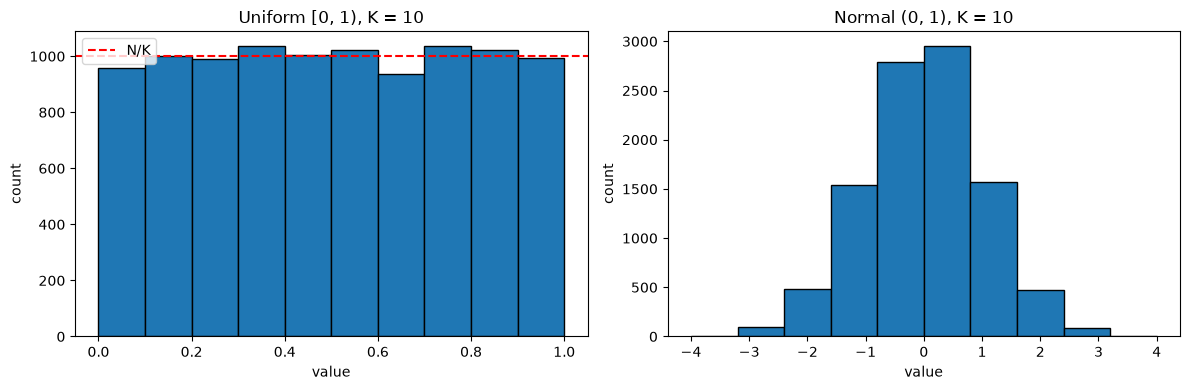

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))     

axes[0].bar(edges_u[:-1], counts_u, width=np.diff(edges_u), align='edge', edgecolor='black')
axes[0].axhline(len(u) / (len(edges_u) - 1), color='red', linestyle='--', label='N/K')
axes[0].set_title('Uniform [0, 1), K = 10')
axes[0].set_xlabel('value')
axes[0].set_ylabel('count')
axes[0].legend()

axes[1].bar(edges_z[:-1], counts_z, width=np.diff(edges_z), align='edge', edgecolor='black')
axes[1].set_title('Normal (0, 1), K = 10')
axes[1].set_xlabel('value')
axes[1].set_ylabel('count')

plt.tight_layout()
plt.show()

We plot these two binned arrays. As it can be seen, their characteristic distributions are visible(normal and uniform) but these do not exactly represent their distribution perfectly. This is due to the noise that is present(1/√(N·p)). This is not a problem as we expected noise. Binning sets the resolution (a staircase instead of a smooth curve), while finite N causes the random deviations

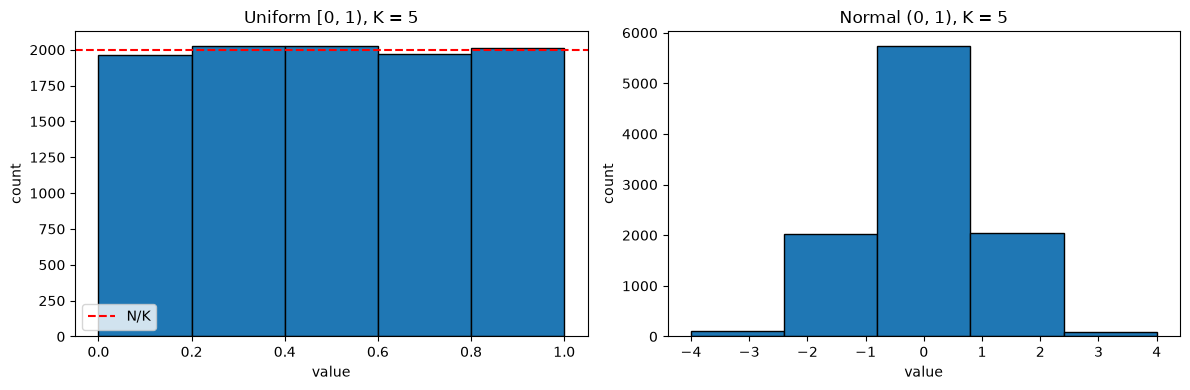

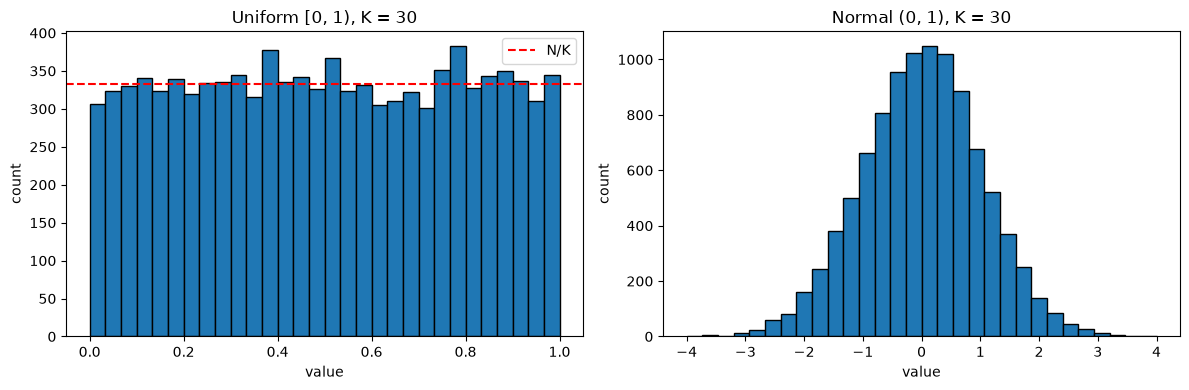

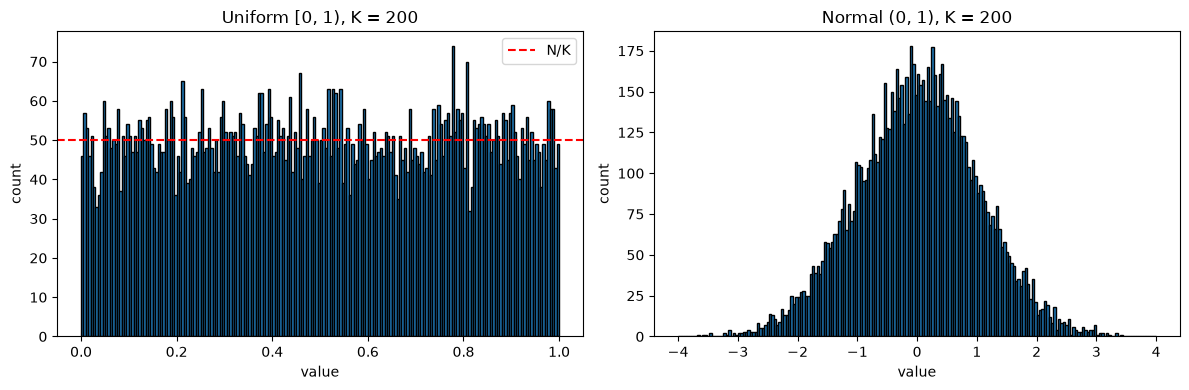

In [14]:
def bin_and_plot(K):
    edges_u = np.linspace(0, 1, K + 1)     
    counts_u = my_bin_counts(u, edges_u)
    edges_z = np.linspace(-4, 4, K + 1)     
    counts_z = my_bin_counts(z, edges_z)
    

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))     
    
    axes[0].bar(edges_u[:-1], counts_u, width=np.diff(edges_u), align='edge', edgecolor='black')
    axes[0].axhline(len(u) / (len(edges_u) - 1), color='red', linestyle='--', label='N/K')
    axes[0].set_title(f'Uniform [0, 1), K = {K}')
    axes[0].set_xlabel('value')
    axes[0].set_ylabel('count')
    axes[0].legend()
    
    axes[1].bar(edges_z[:-1], counts_z, width=np.diff(edges_z), align='edge', edgecolor='black')
    axes[1].set_title(f'Normal (0, 1), K = {K}')
    axes[1].set_xlabel('value')
    axes[1].set_ylabel('count')
    
    plt.tight_layout()
    plt.show()

for K in [5, 30, 200]:
    bin_and_plot(K) 

Uniform looks flat with every bin near N/K and Normal looks like a bell curve that is symmetric that peaks at zero with small tails. With few bins (K = 5) normal is only 5-steps which is too coarse. With many bins (K = 200) we see a more characteristic curve but noise increases, because each bin holds fewer points (N/K), and the relative noise grows like √(K/N): about 2% at K = 5 versus 14% at K = 200. We observe that K ≈ 30 gives the best balance.

## Item 3 — RMSE function

In [15]:
def rmse(y_hat, y):
    
    y_hat = np.asarray(y_hat, dtype=float)
    y = np.asarray(y, dtype=float)
    if y_hat.shape != y.shape:
        raise ValueError(f"Shape mismatch: y_hat {y_hat.shape} vs y {y.shape}")
    return np.sqrt(np.mean((y_hat - y) ** 2))

We convert y_hat and y to float arrays for precaution purposes(in the future, a python list may be passed to this function).
Then we check the shapes and raise error if they don't match. If they match, the function returns the RMSE. 

In [16]:
import numpy as np
y_test = np.array([1.0, 2.0, 3.0, 4.0])

print("perfect prediction:", rmse(y_test, y_test))       # expect 0.0
print("constant offset 3 :", rmse(y_test + 3, y_test))   # expect 3.0

try:
    rmse(np.array([1.0, 2.0]), y_test)                   # wrong length
except ValueError as e:
    print("shape check works:", e)

perfect prediction: 0.0
constant offset 3 : 3.0
shape check works: Shape mismatch: y_hat (2,) vs y (4,)


We conduct a test with known answers beforehand.

In [17]:
rng = np.random.default_rng(1)
data = rng.normal(50, 10, 10_000)      
rng.shuffle(data)                      
splits = np.array_split(data, 5)      

print(f"{'split':>5} {'my rmse':>9} {'one-liner':>10} {'std':>9} {'std ddof=1':>11}")
for k, part in enumerate(splits):
    y_hat  = np.full_like(part, part.mean())             
    r_mine = rmse(y_hat, part)
    r_demo = np.sqrt(np.mean((part.mean() - part) ** 2))  
    s_pop  = np.std(part)                                 
    s_samp = np.std(part, ddof=1)                         
    print(f"{k:>5} {r_mine:>9.4f} {r_demo:>10.4f} {s_pop:>9.4f} {s_samp:>11.4f}")

split   my rmse  one-liner       std  std ddof=1
    0    9.7321     9.7321    9.7321      9.7346
    1   10.0384    10.0384   10.0384     10.0409
    2   10.0968    10.0968   10.0968     10.0994
    3    9.9924     9.9924    9.9924      9.9949
    4   10.0561    10.0561   10.0561     10.0586


We generate a seeded rng and we define a normal distribution with mean = 50 and std = 10. Then we shuffle the data. After that, we split the data into 5 pieces so every piece gives arrays of 2000 values.
Then we make the array same shape as part with its mean. 
We observe that in the output, first three columns return the same values. This is due to the fact that we picked ŷ = mean and in result the RMSE formula gives standard deviation with factor 1/n so it matches np.std with ddof=0. In column four, we see a different number, this is due to Bessel's correction. 
It can also be observed that all values are around 10. This is due to our choice of std=10. In conclusion, we predicted the mean and only recovered 
the noise level (std=10). That is the noise floor, which no model can beat. 
    

# Item 4 — Data collection exercise

## 4.1 Problem and table sketch
**Problem:** Predict the compressive strength of concrete from its mix proportions and its age.
This matters because strength is only known after days of curing and a destructive test;
a model could screen mix designs before casting.

**One row per:** one compressive-strength test of one concrete mix at one age.
Note: the same mix can appear at several ages → rows are *not* fully independent (slide 9).

| Column | Type | Unit | Role |
|---|---|---|---|
| cement | numerical, continuous | kg/m³ | feature |
| slag (blast furnace slag) | numerical, continuous | kg/m³ | feature |
| fly_ash | numerical, continuous | kg/m³ | feature |
| water | numerical, continuous | kg/m³ | feature |
| superplasticizer | numerical, continuous | kg/m³ | feature |
| coarse_agg | numerical, continuous | kg/m³ | feature |
| fine_agg | numerical, continuous | kg/m³ | feature |
| age_days | numerical, discrete | day | feature |
| strength_MPa | numerical, continuous | MPa | **target** |

## 4.2 Source
**Database** (slide 14, third source type): UCI Machine Learning Repository,
"Concrete Compressive Strength", I-Cheng Yeh (1998), DOI 10.24432/C5PK67, licence CC BY 4.0.
Original study: I-C. Yeh, *Cement and Concrete Research* 28(12), 1798–1808 (1998).
Downloaded: 2 November 2026. Raw files kept unchanged in `raw/`.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Load — first three calls on any new table: shape, head(), dtypes 
`raw` is never modified; all cleaning happens on the copy `df`.

In [19]:
raw = pd.read_excel('./raw/Concrete_Data.xls')
df = raw.copy()

print(raw.shape)
print(raw.columns.tolist())

(1030, 9)
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) ']


In [20]:
raw.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [21]:
raw.dtypes

Cement (component 1)(kg in a m^3 mixture)                float64
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    float64
Fly Ash (component 3)(kg in a m^3 mixture)               float64
Water  (component 4)(kg in a m^3 mixture)                float64
Superplasticizer (component 5)(kg in a m^3 mixture)      float64
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     float64
Fine Aggregate (component 7)(kg in a m^3 mixture)        float64
Age (day)                                                  int64
Concrete compressive strength(MPa, megapascals)          float64
dtype: object

## 4.3 Cleanup 

### (4) Improper format: the header
The original column names contain the unit, a component number, double spaces
(`'Water  (component 4)...'`, `'Coarse Aggregate  (component 6)...'`) and a trailing space
(`'...megapascals) '`). They are hard to type and a single missing space gives a KeyError.
**Decision:** rename to short names; the units move to the metadata file

Renaming is done by position, after checking there are exactly 9 columns in the documented order.

Also visible in `head()`: rows 2 and 3 are the same mix tested at 270 and 365 days —
the same mix appears at several ages.

In [22]:
assert raw.shape[1] == 9, "unexpected number of columns - check the file"

new_names = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
             'coarse_agg', 'fine_agg', 'age_days', 'strength_MPa']
df.columns = new_names
df.describe()

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age_days,strength_MPa
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


### (1) Incorrect: impossible values and a physics check
- Masses and strength cannot be negative.
- Physics check : the components of 1 m³ of concrete should add up
  to roughly the density of concrete, about 2200–2500 kg/m³. Rows far outside are
  **flagged, not deleted**, unless a cause is found.

negative values: 0
count    1030.000000
mean     2343.515199
std        65.362861
min      2194.600000
25%      2291.150000
50%      2349.000000
75%      2390.270000
max      2551.000000
Name: total_kg_m3, dtype: float64
0 rows outside 2100-2600 kg/m3


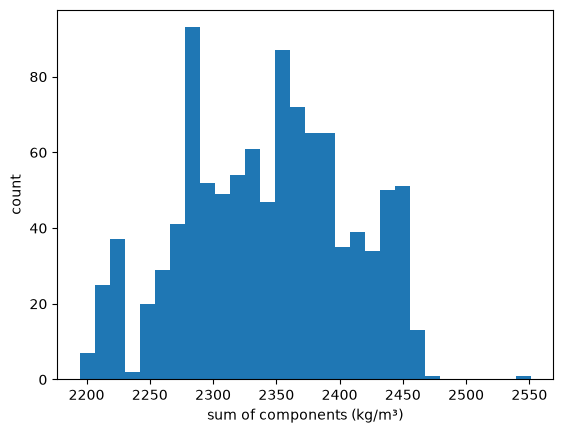

In [23]:
print('negative values:', (df < 0).sum().sum())

components = new_names[:7]
df['total_kg_m3'] = df[components].sum(axis=1)
print(df['total_kg_m3'].describe())

suspicious = df[(df['total_kg_m3'] < 2100) | (df['total_kg_m3'] > 2600)]
print(len(suspicious), 'rows outside 2100-2600 kg/m3')

plt.hist(df['total_kg_m3'], bins=30)
plt.xlabel('sum of components (kg/m³)')
plt.ylabel('count')
plt.show()

In [24]:
df[df['total_kg_m3'] > 2500]

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age_days,strength_MPa,total_kg_m3
69,485.0,0.0,0.0,146.0,0.0,1120.0,800.0,28,71.988189,2551.0


**Result:** no negative values. The components sum to 2194.6–2551.0 kg/m³ (mean 2343.5),
the normal density range of concrete, so **0 rows are flagged** and none is removed at this step.
One mix (~2551 kg/m³) sits apart from the rest in the histogram, but it is still physically plausible:
So it is **kept**.

### (2) Incomplete: missing values and the meaning of zero
`isnull()` finds NaN. But many rows have **0** for slag, fly ash or superplasticizer
(their 25 % value in `describe()` is already 0).
Unlike the 30 °C in the fatigue data (a sentinel for "not done"), **0 kg/m³ here is a true physical value**:
the component was not added, and "zero added" is exactly what the number says.
**Decision:** keep the zeros as numbers; do not replace them with NaN.

In [25]:
print(df.isnull().sum())
for c in ['slag', 'fly_ash', 'superplasticizer']:
    print(f"{c}: {(df[c] == 0).mean():.0%} of rows are 0")

cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_agg          0
fine_agg            0
age_days            0
strength_MPa        0
total_kg_m3         0
dtype: int64
slag: 45% of rows are 0
fly_ash: 55% of rows are 0
superplasticizer: 37% of rows are 0


In [26]:
n_dup = df.duplicated(subset=new_names).sum()
print(n_dup, 'exact duplicate rows')
df[df.duplicated(subset=new_names, keep=False)].sort_values(new_names).head(10)

25 exact duplicate rows


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age_days,strength_MPa,total_kg_m3
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435,2332.0
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435,2332.0
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171,2428.6
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171,2428.6
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171,2428.6
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171,2428.6
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819,2428.6
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819,2428.6
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819,2428.6
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713,2428.6


In [27]:
df = df.drop_duplicates(subset=new_names).reset_index(drop=True)
print('after dropping:', df.shape)

after dropping: (1005, 10)


**Result:** 25 exact duplicate rows were found and dropped (1030 → 1005 rows).
They come in groups: e.g. rows 83, 86, 88 and 91 are the same mix at the same age (3 days) with the same strength
to six decimals (35.301171 MPa). Independent replicate tests cannot agree to 0.000001 MPa, so these are either
copied entries or one averaged value repeated. Keeping them would give these mixes 2–4× more weight in a fit
than the others. Which explanation is correct is not stated in the source (→ 4.6).

### Structure check: how many distinct mixes?
Same mix proportions at different ages = one mix tested several times (a short time series per mix)
A `mix_id` lets a later train/test split keep all ages of one mix together; otherwise the test set would contain
mixes the model already saw (leakage).

In [28]:
df['mix_id'] = df.groupby(components).ngroup()
print(df['mix_id'].nunique(), 'distinct mixes in', len(df), 'rows')
print('ages per mix:')
print(df.groupby('mix_id').size().value_counts().sort_index())
print('ages tested:', sorted(df['age_days'].unique()))

428 distinct mixes in 1005 rows
ages per mix:
1    246
2     42
3      7
4     38
5     77
6     12
7      3
8      3
Name: count, dtype: int64
ages tested: [np.int64(1), np.int64(3), np.int64(7), np.int64(14), np.int64(28), np.int64(56), np.int64(90), np.int64(91), np.int64(100), np.int64(120), np.int64(180), np.int64(270), np.int64(360), np.int64(365)]


### A first descriptor and a physics sanity check 
Abrams' law: strength falls as the **water-to-cement ratio** w/c rises. If the data are physical, the scatter should
show this trend, with older specimens stronger at the same w/c. `scatter`, not `plot`: rows are independent samples.

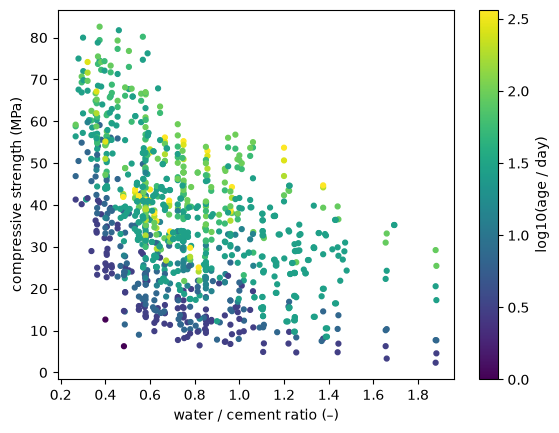

In [29]:
df['w_c'] = df['water'] / df['cement']

sc = plt.scatter(df['w_c'], df['strength_MPa'], c=np.log10(df['age_days']), s=12, cmap='viridis')
plt.colorbar(sc, label='log10(age / day)')
plt.xlabel('water / cement ratio (–)')
plt.ylabel('compressive strength (MPa)')
plt.show()

**Result (structure):** 1005 rows come from only **428 distinct mixes**. 246 mixes were tested at one age;
182 mixes were tested at 2–8 ages and make up 759 rows (~76 %). 14 ages from 1 to 365 days.
→ The rows are not independent: the effective number of samples is closer to 428 than to 1005,
and any future train/test split must keep all ages of a mix on the same side (split by `mix_id`).

**Result (physics):** strength falls as w/c rises (≈ 60–80 MPa at w/c ≈ 0.3, < 35 MPa at w/c ≈ 1.8),
and at the same w/c older specimens are stronger. Both agree with Abrams' law and with curing,
so the data behave physically. At fixed w/c and age the spread is still ~20–30 MPa, so the other
components (slag, fly ash, superplasticizer) must matter too.

### Save the processed data
`total_kg_m3` was only a check and is removed; `mix_id` and `w_c` are kept as derived columns.

In [30]:
del df['total_kg_m3']
df.to_csv('./processed/concrete_clean.csv', index=False)
print('saved', df.shape)

saved (1005, 11)


## 4.4 Metadata file next to the data 

In [31]:
%%writefile metadata.yaml
dataset: Concrete compressive strength vs mix proportions and age
source:
  repository: UCI Machine Learning Repository
  name: Concrete Compressive Strength
  creator: I-Cheng Yeh
  doi: 10.24432/C5PK67
  licence: CC BY 4.0
  original_paper: "Yeh, I-C. (1998) Cement and Concrete Research 28(12)"
  downloaded: 2026-11-02
raw_files: [raw/Concrete_Data.xls, raw/Concrete_Readme.txt]
row_definition: one compressive-strength test of one mix at one age
columns:
  cement:           {unit: kg/m3, type: float}
  slag:             {unit: kg/m3, type: float, note: "0 = not added (true value)"}
  fly_ash:          {unit: kg/m3, type: float, note: "0 = not added (true value)"}
  water:            {unit: kg/m3, type: float}
  superplasticizer: {unit: kg/m3, type: float, note: "0 = not added (true value)"}
  coarse_agg:       {unit: kg/m3, type: float}
  fine_agg:         {unit: kg/m3, type: float}
  age_days:         {unit: day, type: int}
  strength_MPa:     {unit: MPa, type: float, role: target}
  mix_id:           {unit: "-", type: int, note: "derived; identical mix proportions share an id"}
  w_c:              {unit: "-", type: float, note: "derived; water / cement"}
missing_value: none in source (NaN would be used)
unknown:
  - test standard, specimen geometry, curing conditions are not given in the source
  - whether duplicate rows are double entries or replicates
  - duplicates come in groups with identical strength to 6 decimals: copies or averaged values?  
processing: raw/Concrete_Data.xls -> HW1 notebook, item 4 -> processed/concrete_clean.csv

Overwriting metadata.yaml


In [32]:
%%writefile .gitignore
.ipynb_checkpoints/
__pycache__/

Overwriting .gitignore


## 4.5 Repository
https://github.com/royyckl2682/hw1-concrete

Structure: `raw/` (untouched download), `processed/` (cleaned CSV), `scripts/`, `metadata.yaml`, this notebook.
Commit 1 (`1d1d335`) contains only the raw data, so every processed number can be traced back to the original file.

## 4.6 Obstacles and open questions
The header mixed units, component numbers, double spaces and a trailing space, so I renamed the columns by position
and moved the units into the metadata file. The source has no missing values and no negative values, and all
mixes pass the density check (2195–2551 kg/m³). But 25 exact duplicate rows had to be dropped (1030 → 1005), and they
come in groups with identical strength to six decimals — nothing in the source says whether they are copied entries
or one averaged value repeated. Zeros in slag (45 % of rows), fly ash (55 %) and superplasticizer (37 %) looked like
a possible sentinel, but here they are true amounts. Important metadata is missing: the test standard, specimen size
and curing conditions, so I cannot check whether all tests are comparable. The 1005 rows come from only 428 mixes
tested at up to 8 ages, so the rows are not independent and any future split must be done by `mix_id`.
Setting up Git and GitHub for the first time was itself an obstacle: A missing quotation mark in git config left the terminal waiting for input, and the project folder was not where File Explorer’s Documents pointed.